ATIVIDADE 8

IMPORTAÇÕES

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt



df_customers = pd.read_csv("customers-10000.csv")

REGIÃO MAIS VENDIDA

O pais com mais clientes é o(a) Korea com 84.
O pais com menos clientes é o(a) Antarctica (the territory South of 60 deg S) com 26.
A cidade com mais clientes é o(a) Henrymouth com 4.
Country
Korea                           84
Congo                           81
Vanuatu                         58
Sierra Leone                    56
Montenegro                      54
Cote d'Ivoire                   54
United States Virgin Islands    54
Mauritius                       54
Andorra                         54
Botswana                        53
Name: Customer Id, dtype: int64


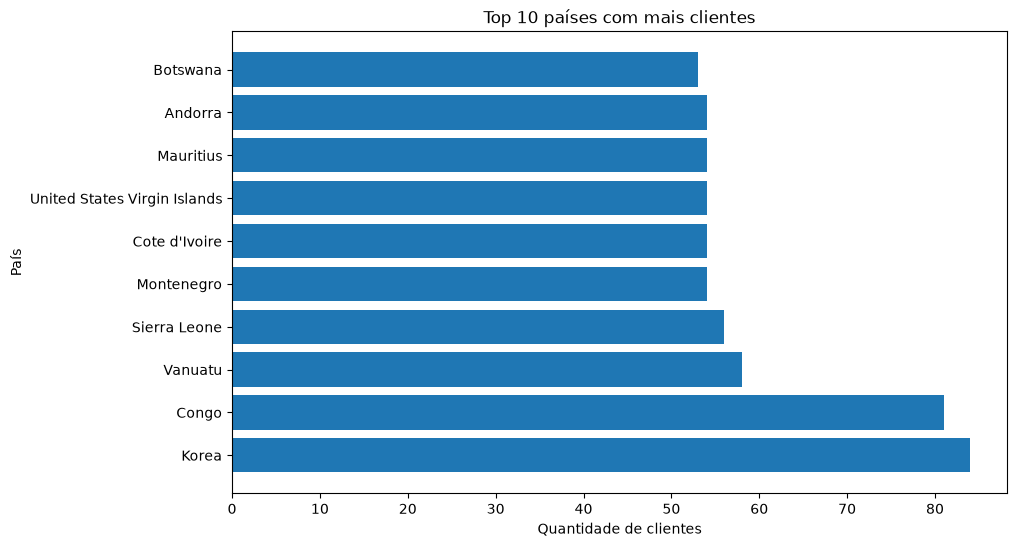

In [6]:
contagem_country = df_customers.groupby("Country")["Customer Id"].count().sort_values(ascending=False)

#print(contagem_country)

maior_pais = contagem_country.idxmax()
mais_pais = contagem_country.max()
print(f"O pais com mais clientes é o(a) {maior_pais} com {mais_pais}.")

menor_pais = contagem_country.idxmin()
menos_pais = contagem_country.min()
print(f"O pais com menos clientes é o(a) {menor_pais} com {menos_pais}.")

contagem_city = df_customers.groupby("City")["Customer Id"].count().sort_values(ascending=False)

#print(contagem_city)

maior_cidade = contagem_city.idxmax()
mais_cidade = contagem_city.max()
print(f"A cidade com mais clientes é o(a) {maior_cidade} com {mais_cidade}.")

top_country = df_customers.groupby("Country")["Customer Id"].count().sort_values(ascending=False).head(10)
print(top_country)

plt.figure(figsize=(10, 6))

plt.barh(top_country.index, top_country.values)

plt.title("Top 10 países com mais clientes")
plt.xlabel("Quantidade de clientes")
plt.ylabel("País")

plt.show()

DATAS DE MAIOR VENDA

Subscription Date
2020-04-13    24
2021-10-04    22
2021-12-15    22
2020-07-27    21
2022-01-19    21
              ..
2020-07-13     4
2021-12-23     4
2020-06-01     4
2021-02-24     4
2021-02-15     2
Name: Customer Id, Length: 880, dtype: int64
A data de maior venda é em 2020-04-13 00:00:00, com 24 vendas.
Vendas por ano:
Subscription Date
2020    4212
2021    4125
2022    1663
Name: Customer Id, dtype: int64

O ano com maior volume de vendas foi 2020, com 4212 vendas.

Vendas por mês:
Subscription Date
3     1076
1     1060
4      989
5      978
2      931
8      766
12     747
11     723
10     717
7      691
6      666
9      656
Name: Customer Id, dtype: int64

O mês com maior volume de vendas foi o mês 3, com 1076 vendas.


Text(0, 0.5, 'Quantidade de Vendas')

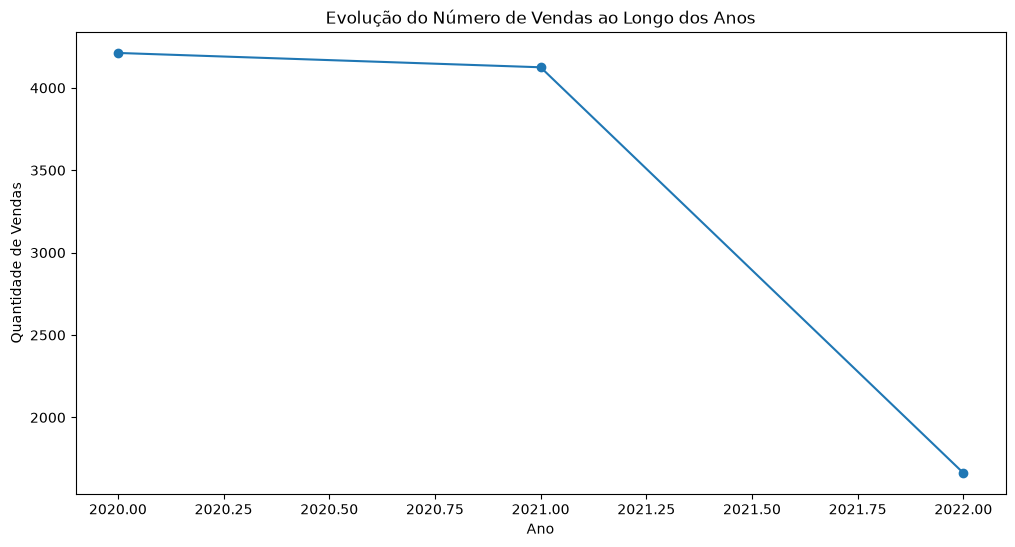

In [14]:
df_customers["Subscription Date"] = pd.to_datetime(
    df_customers["Subscription Date"])

data_venda = df_customers.groupby("Subscription Date")["Customer Id"].count().sort_values(ascending=False)
print(data_venda)

data_maior_venda = data_venda.idxmax()
maior_venda = data_venda.max()

print(f"A data de maior venda é em {data_maior_venda}, com {maior_venda} vendas.")


vendas_por_ano = (
    df_customers.groupby(df_customers["Subscription Date"].dt.year)["Customer Id"]
    .count()
    .sort_values(ascending=False)
)

print("Vendas por ano:")
print(vendas_por_ano)

# Ano com maior volume de vendas
maior_ano = vendas_por_ano.idxmax()
quantidade_ano = vendas_por_ano.max()

print(
    f"\nO ano com maior volume de vendas foi {maior_ano}, "
    f"com {quantidade_ano} vendas."
)


vendas_por_mes = (
    df_customers.groupby(df_customers["Subscription Date"].dt.month)["Customer Id"]
    .count()
    .sort_values(ascending=False)
)

print("\nVendas por mês:")
print(vendas_por_mes)

# Mês com maior volume de vendas
maior_mes = vendas_por_mes.idxmax()
quantidade_mes = vendas_por_mes.max()

print(
    f"\nO mês com maior volume de vendas foi o mês {maior_mes}, "
    f"com {quantidade_mes} vendas."
)


plt.figure(figsize=(12, 6))

plt.plot(
    vendas_por_ano.index,
    vendas_por_ano.values,
    marker="o"
)

plt.title("Evolução do Número de Vendas ao Longo dos Anos")
plt.xlabel("Ano")
plt.ylabel("Quantidade de Vendas")

MAIOR CLIENTE

Empresa_Principal
Mack       24
Cortez     24
Heath      22
Pearson    20
Cochran    19
Name: count, dtype: int64
Empresa_Principal
Mack       24
Cortez     24
Heath      22
Pearson    20
Cochran    19


<BarContainer object of 5 artists>

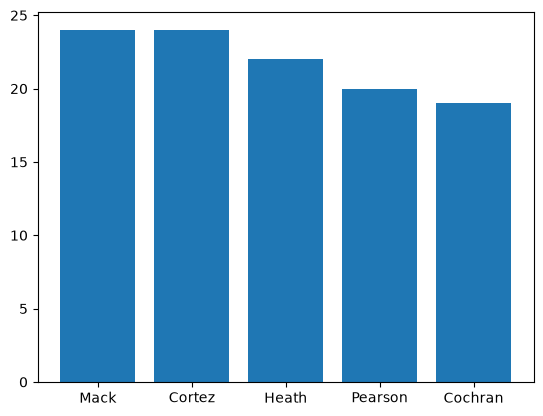

In [26]:
df_customers["Empresa_Principal"] = (df_customers["Company"]
    .str.strip()
    .str.extract(r'^([A-Za-z]+)', expand=False)
    .str.title()
)

#print(df_customers["Empresa_Principal"])

maiores_empresas = df_customers["Empresa_Principal"].value_counts().head()
print(maiores_empresas)
print(maiores_empresas.to_string())

plt.bar(
    maiores_empresas.index,
    maiores_empresas.values
)